In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sqlalchemy as sa
from IPython.display import display

HERE = Path.cwd()

sys.path.insert(0, str(HERE.parent / 'func'))

DB_URL = os.getenv(
    'CRMP_DB_URL',
    'postgresql://tongli1997@proddb01.pcic.uvic.ca,proddb02.pcic.uvic.ca/crmp'
    '?keepalives=1&keepalives_idle=300&keepalives_interval=300'
    '&keepalives_count=9&passfile=/workspaces/crmprtd/.pgpass',
)
engine = sa.create_engine(DB_URL, pool_pre_ping=True)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)

## Network database table

In [2]:
NETWORK_TABLE_SQL = sa.text("""
SELECT
    network_id,
    network_name,
    description,
    virtual,
    publish,
    col_hex,
    contact_id,
    mod_time,
    mod_user
FROM meta_network
ORDER BY network_id
""")

network_table = pd.read_sql(NETWORK_TABLE_SQL, engine)
# display(network_table)

## Station statistics

PCDS stores the station identity in `meta_station` and the time-varying station metadata (name, location, operating dates, etc.) in `meta_history`. One station can therefore have several history rows. All counts below use distinct `station_id` values.

A station is counted as **active** when `obs_raw` contains at least one observation for it since January 1 of the database server's current year.

A station is counted as metadata-updated this year when its station identity or any associated history was inserted, updated, or deleted on or after January 1 of the database server's current year. The append-only `meta_station_hx` and `meta_history_hx` audit tables make this robust to deleted history rows. This measures metadata changes, not recent observations (`max_obs_time`).

In [3]:
STATION_STATISTICS_SQL = sa.text("""
WITH boundaries AS (
    SELECT date_trunc('year', CURRENT_DATE)::timestamp AS year_start
),
observed_this_year AS (
    SELECT
        h.station_id,
        MAX(o.obs_time) AS latest_observation
    FROM obs_raw AS o
    JOIN meta_history AS h ON h.history_id = o.history_id
    CROSS JOIN boundaries AS b
    WHERE o.obs_time >= b.year_start
    GROUP BY h.station_id
),
per_station AS (
    SELECT
        s.station_id,
        EXISTS (
            SELECT 1 FROM meta_station_hx AS sh, boundaries AS b
            WHERE sh.station_id = s.station_id
              AND sh.mod_time >= b.year_start
        ) OR EXISTS (
            SELECT 1 FROM meta_history_hx AS hh, boundaries AS b
            WHERE hh.station_id = s.station_id
              AND hh.mod_time >= b.year_start
        ) AS metadata_updated_this_year
    FROM meta_station AS s
)
SELECT
    b.year_start::date AS updated_since,
    COUNT(*) AS total_stations,
    COUNT(*) FILTER (WHERE o.station_id IS NOT NULL) AS active_stations,
    MAX(o.latest_observation) AS latest_active_observation,
    COUNT(*) FILTER (WHERE p.metadata_updated_this_year)
        AS stations_metadata_updated_this_year
FROM per_station AS p
LEFT JOIN observed_this_year AS o ON o.station_id = p.station_id
CROSS JOIN boundaries AS b
GROUP BY b.year_start
""")

station_statistics = pd.read_sql(STATION_STATISTICS_SQL, engine)
display(station_statistics)

,updated_since,total_stations,active_stations,latest_active_observation,stations_metadata_updated_this_year
0,2026-01-01,10126,1346,2026-11-03 07:00:00,1337


### Breakdown by network

This uses the same definitions as the overall result. The sum of network totals should equal `total_stations`; the anomaly column helps validate the active-station count.

In [4]:
NETWORK_STATISTICS_SQL = sa.text("""
WITH boundaries AS (
    SELECT date_trunc('year', CURRENT_DATE)::timestamp AS year_start
),
observed_this_year AS (
    SELECT
        h.station_id,
        MAX(o.obs_time) AS latest_observation
    FROM obs_raw AS o
    JOIN meta_history AS h ON h.history_id = o.history_id
    CROSS JOIN boundaries AS b
    WHERE o.obs_time >= b.year_start
    GROUP BY h.station_id
),
per_station AS (
    SELECT
        s.station_id,
        s.network_id,
        EXISTS (
            SELECT 1 FROM meta_station_hx AS sh, boundaries AS b
            WHERE sh.station_id = s.station_id
              AND sh.mod_time >= b.year_start
        ) OR EXISTS (
            SELECT 1 FROM meta_history_hx AS hh, boundaries AS b
            WHERE hh.station_id = s.station_id
              AND hh.mod_time >= b.year_start
        ) AS metadata_updated_this_year
    FROM meta_station AS s
)
SELECT
    n.network_id,
    n.network_name,
    COUNT(*) AS total_stations,
    COUNT(*) FILTER (WHERE o.station_id IS NOT NULL) AS active_stations,
    MAX(o.latest_observation) AS latest_active_observation,
    COUNT(*) FILTER (WHERE p.metadata_updated_this_year)
        AS metadata_updated_this_year
FROM per_station AS p
LEFT JOIN observed_this_year AS o ON o.station_id = p.station_id
JOIN meta_network AS n ON n.network_id = p.network_id
CROSS JOIN boundaries AS b
GROUP BY n.network_id, n.network_name
ORDER BY total_stations DESC, n.network_id
""")

network_statistics = pd.read_sql(NETWORK_STATISTICS_SQL, engine)
display(network_statistics)

,network_id,network_name,total_stations,active_stations,latest_active_observation,metadata_updated_this_year
0,1,EC,3656,0,NaT,0
1,17,ARDA,3206,0,NaT,0
2,12,FLNRO-WMB,856,329,2026-11-03 01:00:00,298
3,19,EC_raw,456,391,2026-11-03 07:00:00,241
4,9,ENV-AQN,409,120,2026-10-31 22:00:00,195
5,5,BCH,232,96,2026-10-27 12:30:00,128
6,2,MoTIe,220,192,2026-11-03 07:00:00,54
7,22,ARD,178,0,NaT,0
8,3,MoTIm,174,0,NaT,0
9,14,ENV-ASP,169,113,2026-11-03 07:00:00,87


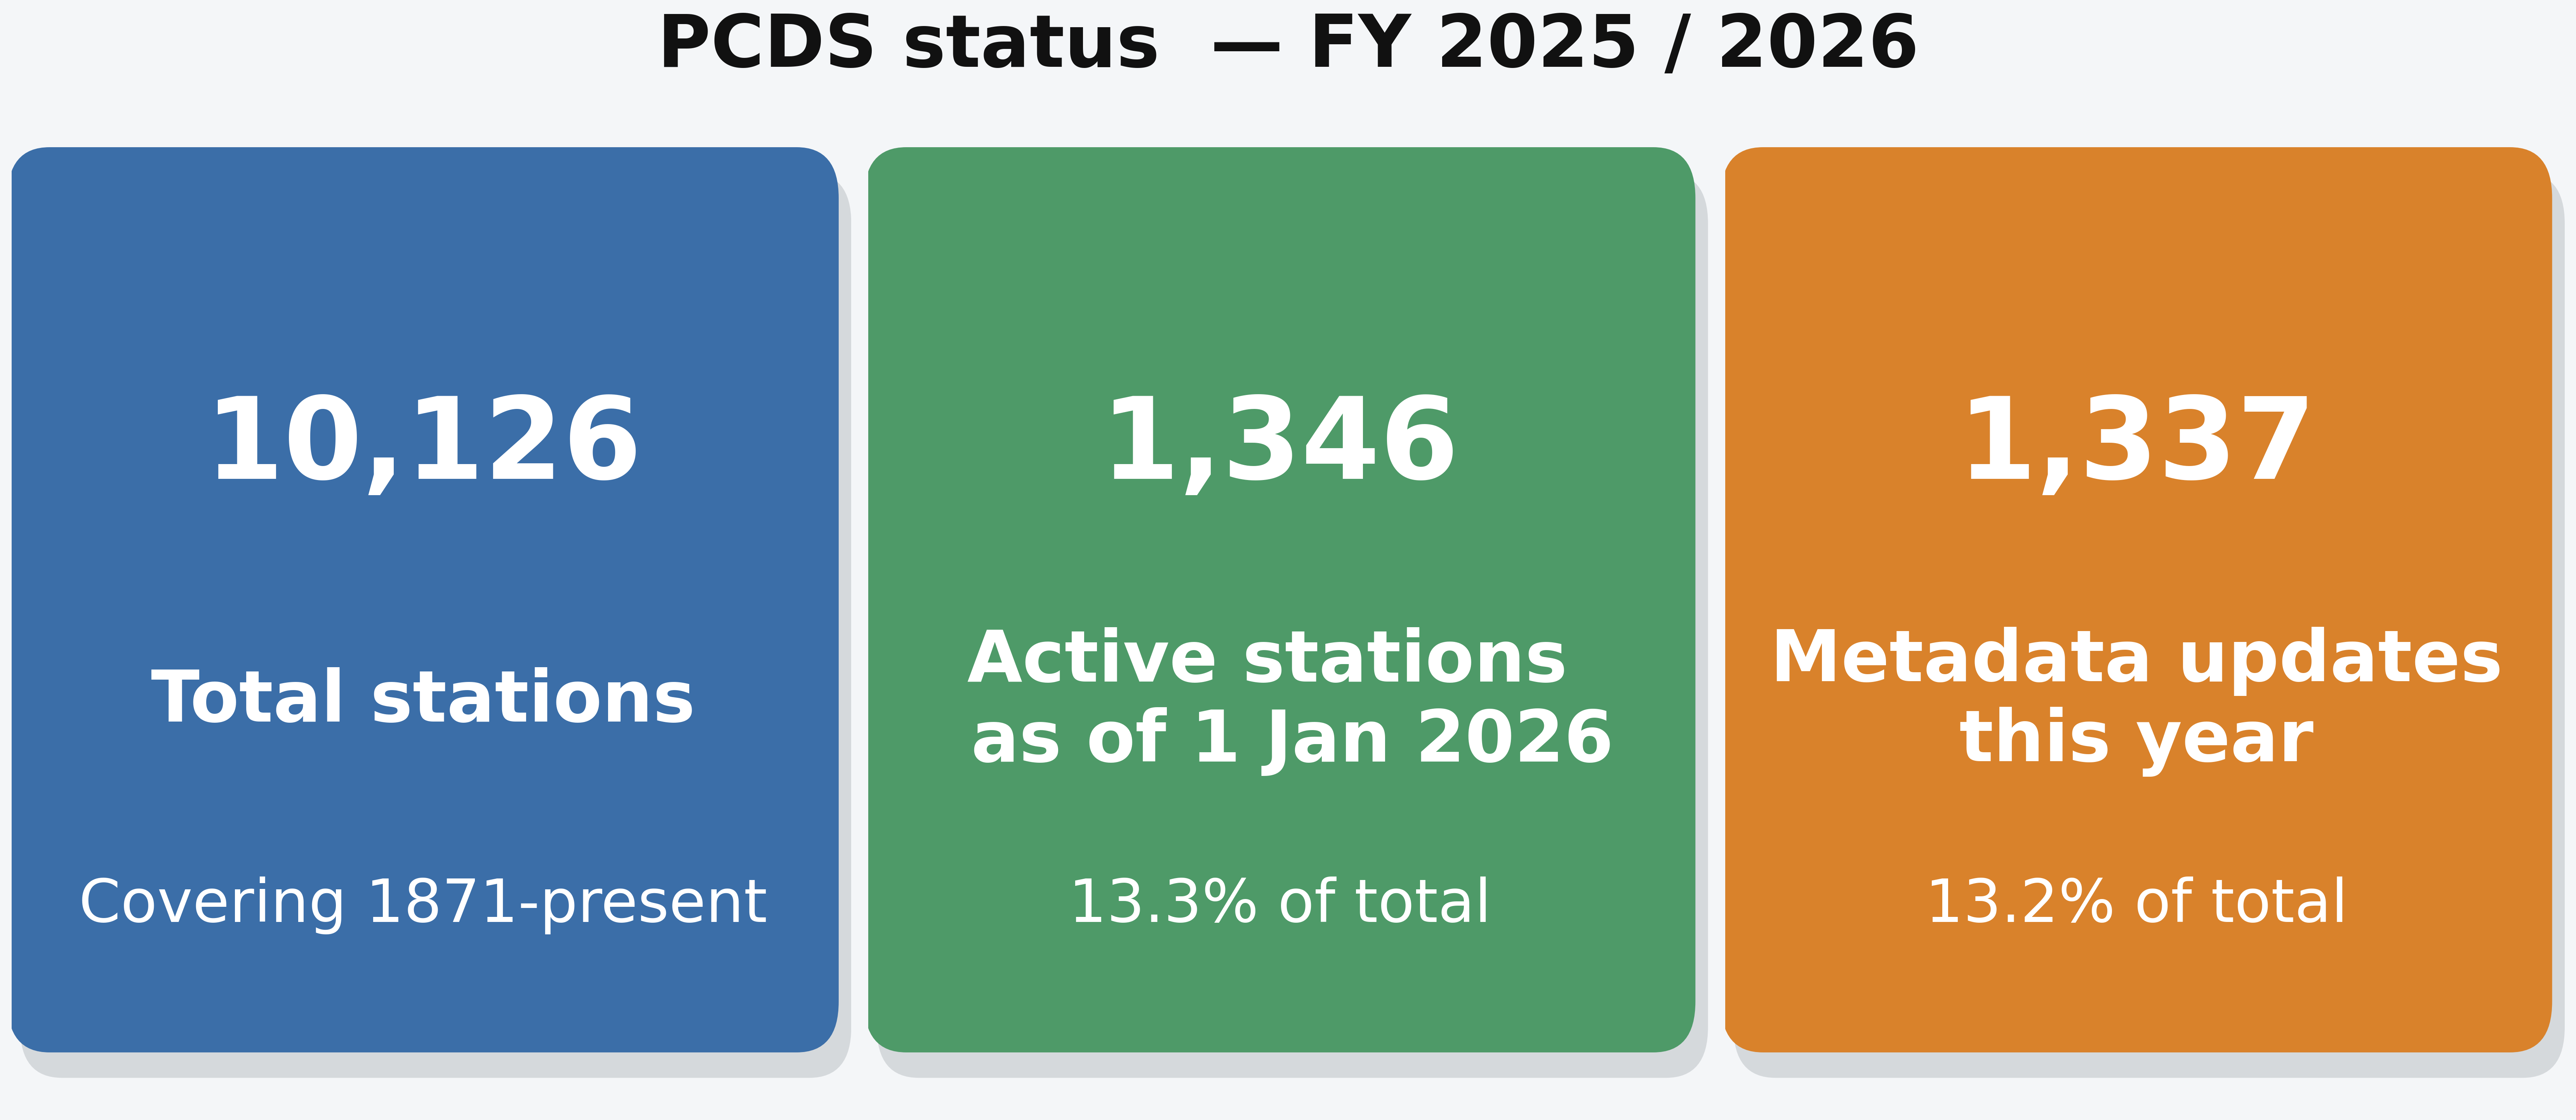

In [8]:
# Visual summary
from matplotlib.patches import FancyBboxPatch
summary = station_statistics.iloc[0]
network_plot = network_statistics.sort_values(
    'total_stations', ascending=True
).reset_index(drop=True)
network_labels = (
    network_plot['network_id'].astype(
        str) + ': ' + network_plot['network_name']
)

total_stations = int(summary['total_stations'])
active_stations = int(summary['active_stations'])
updated_stations = int(summary['stations_metadata_updated_this_year'])
active_share = active_stations / total_stations if total_stations else 0
updated_share = updated_stations / total_stations if total_stations else 0

card_values = [
    ('Total stations', total_stations, 'Covering 1871-present', '#3B6EA8'),
    (
        'Active stations \n as of 1 Jan 2026', active_stations,
        f'{active_share:.1%} of total', '#4E9A68',
    ),
    (
        'Metadata updates\nthis year', updated_stations,
        f'{updated_share:.1%} of total', '#D9822B',
    ),
]

year = pd.Timestamp(summary['updated_since']).year
fig_total, card_axes = plt.subplots(
    1, 3, figsize=(22, 9.5), constrained_layout=True, dpi=300,
)
fig_total.patch.set_facecolor('#F4F6F8')

for ax_card, (label, value, context, color) in zip(card_axes, card_values):
    ax_card.set_facecolor('#F4F6F8')
    shadow = FancyBboxPatch(
        (0.035, 0.055), 0.94, 0.84, transform=ax_card.transAxes,
        boxstyle='round,pad=0.025,rounding_size=0.05',
        linewidth=0, facecolor='#1F2937', alpha=0.14,
    )
    card = FancyBboxPatch(
        (0.02, 0.08), 0.94, 0.84, transform=ax_card.transAxes,
        boxstyle='round,pad=0.025,rounding_size=0.05',
        linewidth=0, facecolor=color,
    )
    ax_card.add_patch(shadow)
    ax_card.add_patch(card)
    ax_card.text(
        0.49, 0.65, f'{value:,}', ha='center', va='center',
        fontsize=70, fontweight='bold', color='white',
    )
    ax_card.text(
        0.49, 0.4, label, ha='center', va='center',
        fontsize=44, fontweight='bold', color='white', wrap=True,
    )
    ax_card.text(
        0.49, 0.20, context, ha='center', va='center',
        fontsize=37, color='white', alpha=1, wrap=True,
    )
    ax_card.set_xticks([])
    ax_card.set_yticks([])
    for spine in ax_card.spines.values():
        spine.set_visible(False)

fig_total.suptitle(
    f'PCDS status  — FY {year - 1} / {year}',
    fontsize=45, fontweight='bold', color='#111111',
)

fig_total.savefig(
    'PCDS_status_summary.pdf',
    format='pdf',
    bbox_inches='tight',
    facecolor=fig_total.get_facecolor(),
)


plt.show()

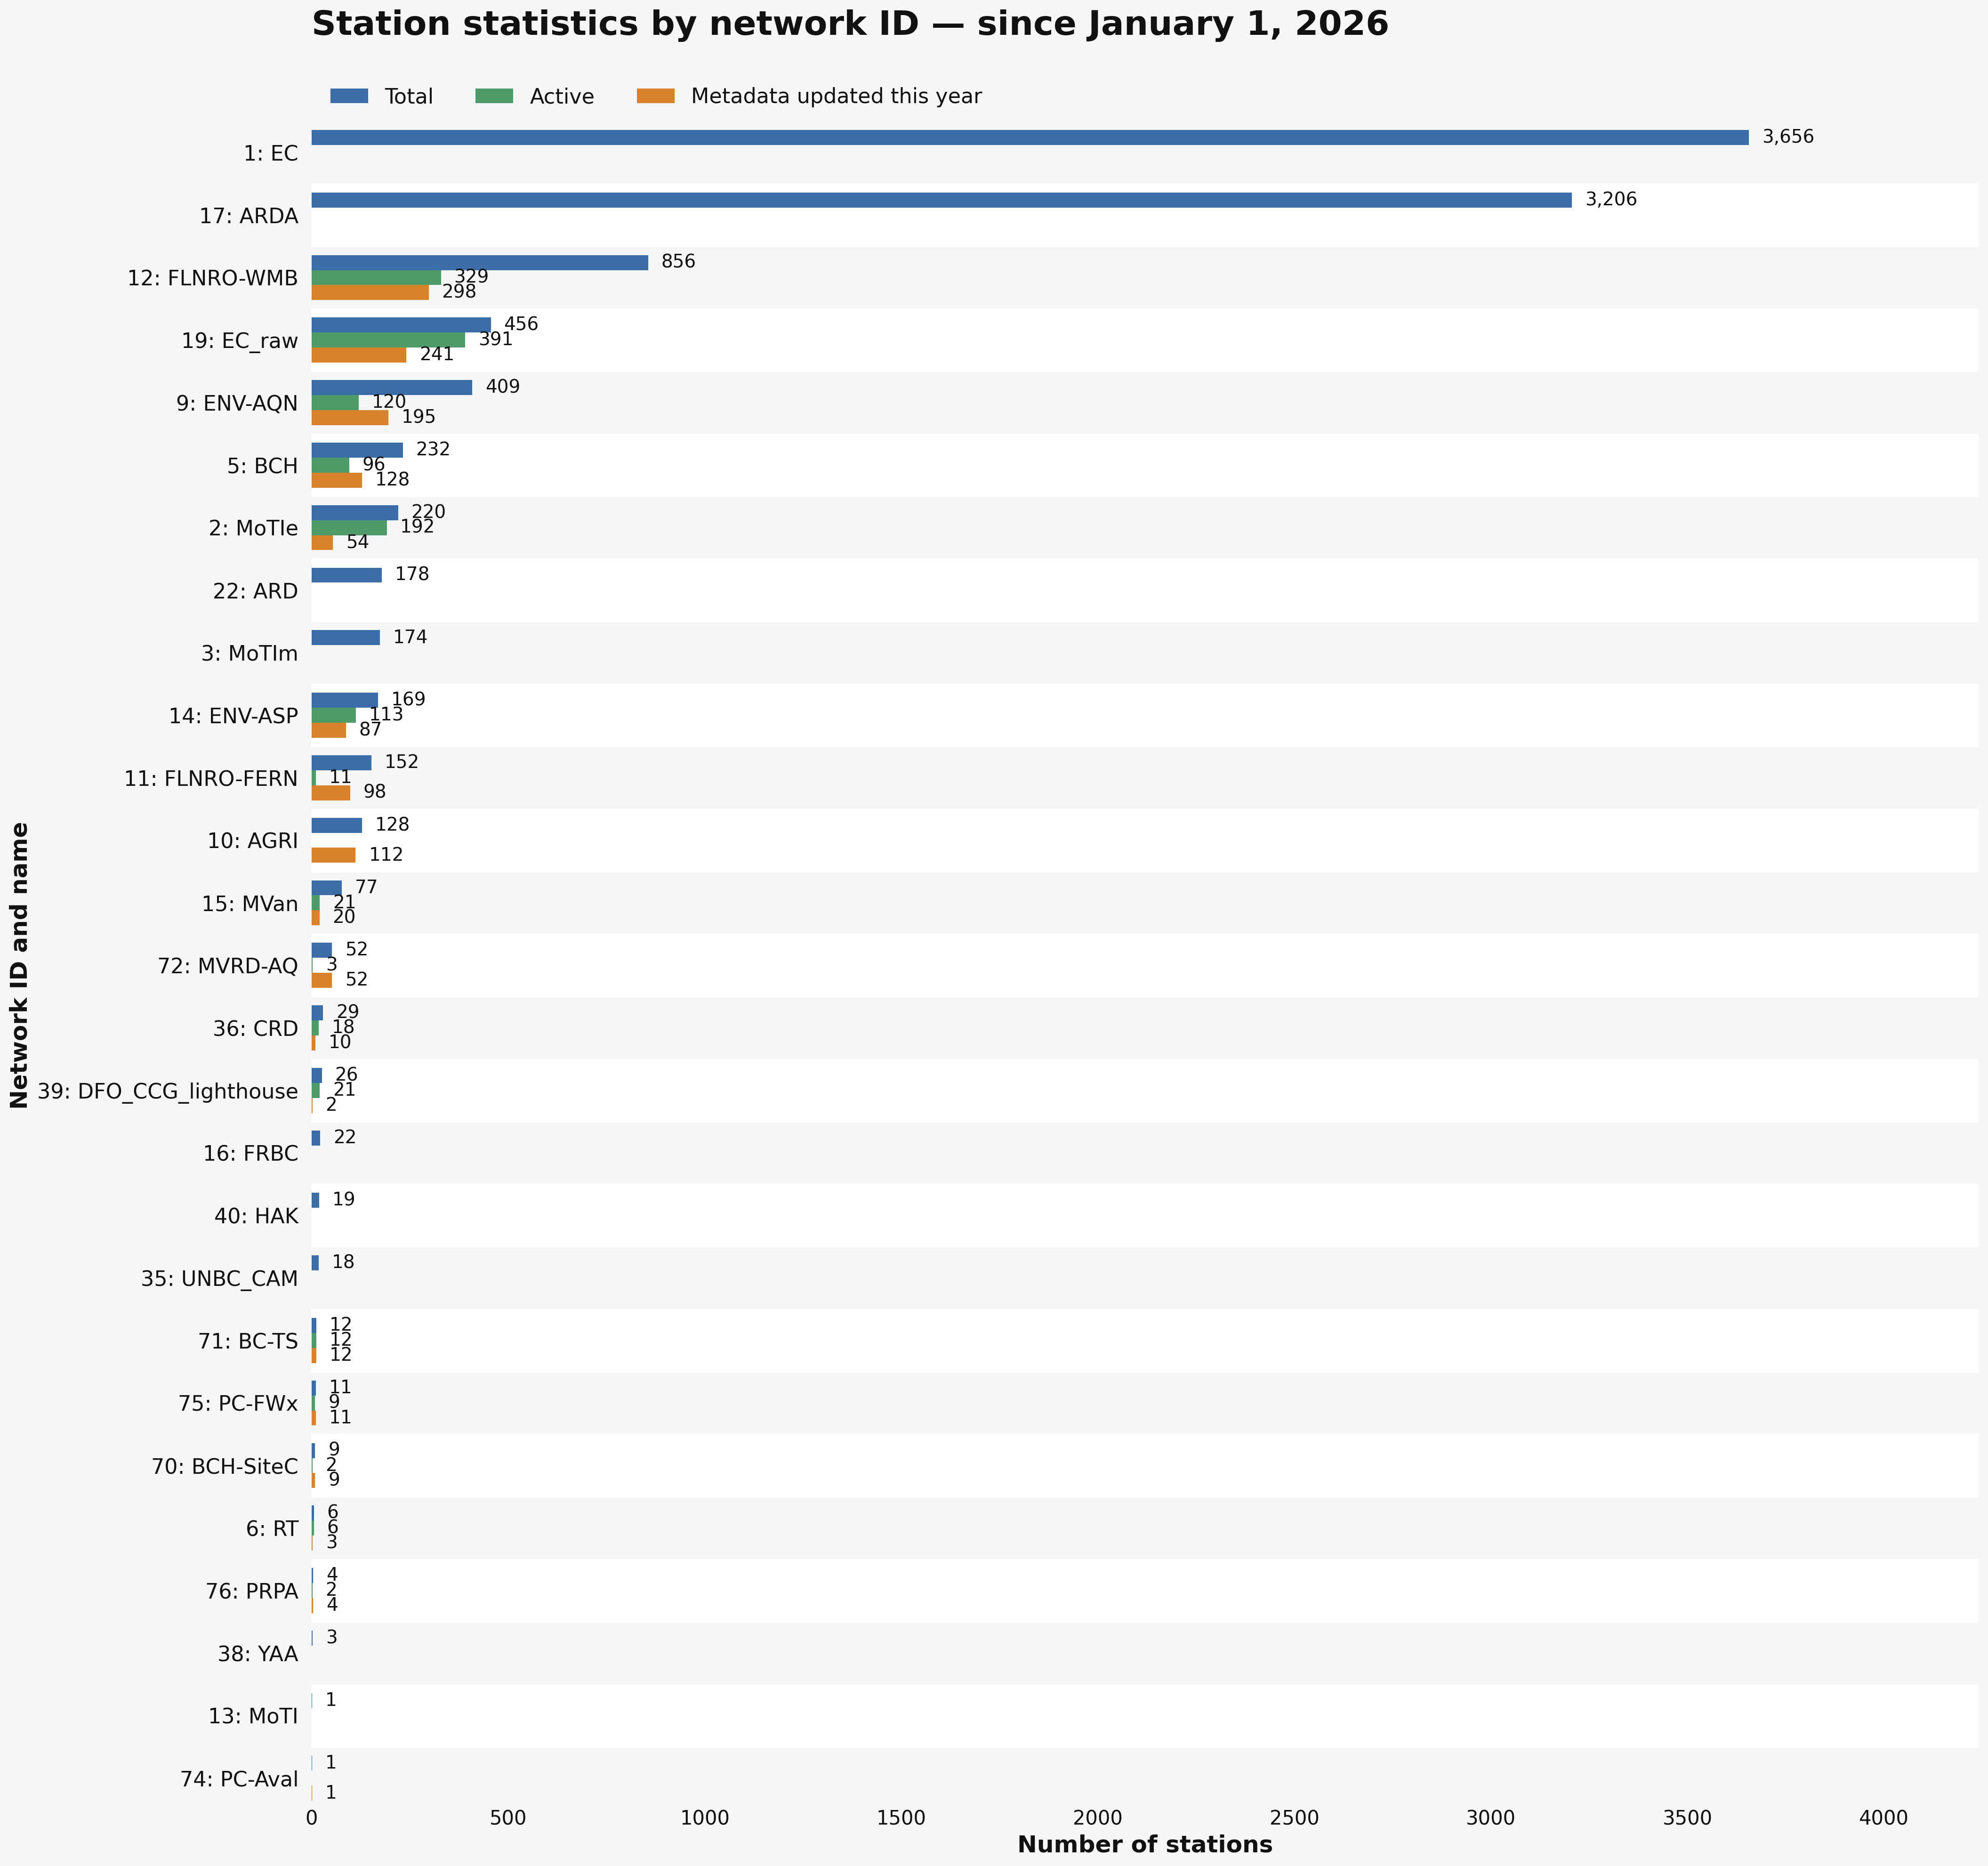

In [6]:

figure_height = max(8, 3.5 + 0.6 * len(network_plot))
fig_network, ax_network = plt.subplots(
    figsize=(21, figure_height), constrained_layout=True, dpi=200,
)
fig_network.patch.set_facecolor('#F4F6F8')
ax_network.set_facecolor('white')
text_color = '#111111'
y_positions = np.arange(len(network_plot))
bar_height = 0.24
for row in range(len(network_plot)):
    if row % 2 == 0:
        ax_network.axhspan(row - 0.48, row + 0.48, color='#F4F6F8', zorder=0)

bars_total = ax_network.barh(
    y_positions + bar_height, network_plot['total_stations'],
    height=bar_height, label='Total', color='#3B6EA8', zorder=3,
)
bars_active = ax_network.barh(
    y_positions, network_plot['active_stations'],
    height=bar_height, label='Active', color='#4E9A68', zorder=3,
)
bars_updated = ax_network.barh(
    y_positions - bar_height, network_plot['metadata_updated_this_year'],
    height=bar_height, label='Metadata updated this year', color='#D9822B', zorder=3,
)
for bars, values in (
    (bars_total, network_plot['total_stations']),
    (bars_active, network_plot['active_stations']),
    (bars_updated, network_plot['metadata_updated_this_year']),
):
    labels = [f'{int(value):,}' if value else '' for value in values]
    ax_network.bar_label(
        bars, labels=labels, padding=10, fontsize=14, color=text_color,
    )
ax_network.set_yticks(y_positions, network_labels)
ax_network.set_xlabel(
    'Number of stations', fontsize=18, fontweight='bold', color=text_color,
)
ax_network.set_ylabel(
    'Network ID and name', fontsize=18, fontweight='bold', color=text_color,
)
ax_network.set_title(
    f'Station statistics by network ID — since January 1, {year}',
    fontsize=26, fontweight='bold', color=text_color, loc='left', pad=70,
)
ax_network.tick_params(axis='x', labelsize=15, colors=text_color)
ax_network.tick_params(
    axis='y', labelsize=16, colors=text_color, length=0, pad=10,
)
ax_network.legend(
    loc='lower left', bbox_to_anchor=(0, 1.00), ncol=3,
    frameon=False, fontsize=16, labelcolor=text_color,
    handlelength=1.8, columnspacing=2.0,
)
ax_network.set_axisbelow(True)
ax_network.grid(axis='x', color='#D1D5DB', linewidth=0.0, alpha=0.75)
ax_network.grid(axis='y', visible=False)
for spine in ax_network.spines.values():
    spine.set_visible(False)
max_total = network_plot['total_stations'].max() if len(network_plot) else 0
ax_network.set_xlim(0, max_total * 1.16 if max_total else 1)
if len(network_plot):
    ax_network.set_ylim(-0.42, len(network_plot) - 0.58)
plt.show()